<a href="https://colab.research.google.com/github/birgulaltug/yapay-zekan-n-etkileri-proje/blob/main/yapayzekan%C4%B1netkileri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** [Birgül Havvanur Altuğ] • **Proje:** [Yapay Zekanın Bireysel Ve Sosyal Etkileri] • **Ekip görevleri:** [Birgül Havvanur Altuğ: veri yapısı, kodlama ve analiz, literatür taraması, veri düzenleme ve raporlama]

Bu notebook başlangıç iskeletidir. Örnek dosya ve kodu kendi araştırma/proje verinize uyarlayın. **Veri uydurup gerçek ölçüm gibi sunmayın.**

## A. Veri tanıtımı
- Veri setinin adı ve bağlantısı: AI Impact on Students — Academic & Well-being Dataset (Kaggle: [https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students])
- Veri kaynağı / lisans / erişim tarihi: Kaggle Açık Veri Arşivi / CC Lisans / 15 Kasım 2026
- CSV mi, JSON mu? CSV
- Satır ve sütunların anlamı: Her bir satır bir öğrenciyi/bireyi temsil eder; sütunlar ise haftalık yapay zeka kullanım saatini (Weekly_GenAI_Hours), ana kullanım amacını (Primary_Use_Case), anksiyete seviyesini ve tükenmişlik risk derecesini (Burnout_Risk_Level) içermektedir.
- Ölçü birimi ve gözlem sayısı: Sayısal saat, anket puanları (1-10 arası) ve kategorik etiketler; toplam 50.000 gözlem birimi.
- Gerçek mi / açık kaynak mı / temsili mi? Açık kaynaklı gerçek araştırma veri setidir.
- Ekip üyelerinin görevleri: Birgül Havvanur Altuğ (Verinin indirilmesi, Colab ortamına aktarılması ve analiz kodlarının yazılması).

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [ ]:
import pandas as pd

# Hatalı veya bozuk satırları atlayarak veriyi güvenle okuyoruz
veri_yolu = "ai_student_impact_dataset (1).csv"
veri = pd.read_csv(veri_yolu, on_bad_lines="skip")

print("Veri seti başarıyla yüklendi!")
print(veri.head())

Veri seti başarıyla yüklendi!
  Student_ID Major_Category Year_of_Study Pre_Semester_GPA Weekly_GenAI_Hours  \
0     100001     Humanities        Senior            2.418              23.31   
1     100002        Medical        Junior            3.821               1.12   
2     100003       Business      Freshman            3.398              21.26   
3     100004       Business        Senior            3.789               1.82   
4     100005           STEM     Sophomore            3.635               9.29   

            Primary_Use_Case Prompt_Engineering_Skill  Tool_Diversity  \
0       Copywriting/Drafting                 Beginner             1.0   
1                   Ideation                 Advanced             5.0   
2        Summarizing_Reading                 Beginner             2.0   
3       Copywriting/Drafting             Intermediate             4.0   
4  Debugging/Troubleshooting                 Advanced             4.0   

  Paid_Subscription Traditional_Study_Hours 

/tmp/ipykernel_1055/2760628153.py:5: DtypeWarning: Columns (0,3,4,8,9,13) have mixed types. Specify dtype option on import or set low_memory=False.
  veri = pd.read_csv(veri_yolu, on_bad_lines="skip")


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [ ]:
import pandas as pd

# 1. Sütun adlarını ve eksik verileri kontrol edelim
print("Sütun Listesi:", veri.columns.tolist())
print("\nEksik Veri Sayıları:\n", veri.isnull().sum())

# 2. Haftalık AI kullanım süresini güvenli bir şekilde sayıya çevirip hesaplayalım
ai_sureleri = pd.to_numeric(veri["Weekly_GenAI_Hours"], errors="coerce")

print("\nToplam Haftalık AI Kullanım Süresi:", ai_sureleri.sum())
print("Ortalama Haftalık AI Kullanım Süresi:", ai_sureleri.mean())

Sütun Listesi: ['Student_ID', 'Major_Category', 'Year_of_Study', 'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours', 'Perceived_AI_Dependency', 'Institutional_Policy', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score', 'Burnout_Risk_Level']

Eksik Veri Sayıları:
 Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            2
Primary_Use_Case              1
Prompt_Engineering_Skill      1
Tool_Diversity                1
Paid_Subscription             1
Traditional_Study_Hours       1
Perceived_AI_Dependency       1
Institutional_Policy          1
Anxiety_Level_During_Exams    1
Post_Semester_GPA             1
Skill_Retention_Score         2
Burnout_Risk_Level            2
dtype: int64

Toplam Haftalık AI Kullanım Süresi: 542511.5
Ortalama Haftalık AI Kullanım Süresi

## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.

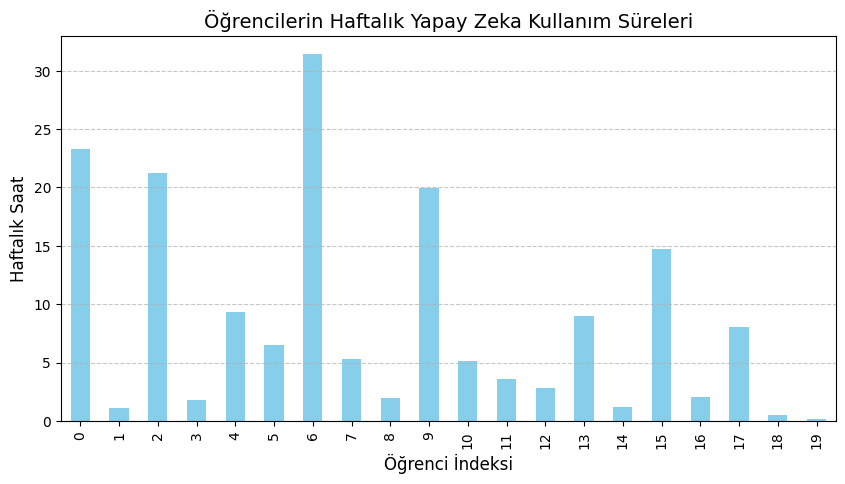

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Sütun adlarındaki olası boşlukları temizleyelim
veri.columns = veri.columns.str.strip()

# Jupyter Notebook içinde grafiğin doğrudan görünmesi için gerekli komut
%matplotlib inline

# İlk 20 öğrencinin haftalık AI kullanım sürelerini gösteren sütun grafiği
plt.figure(figsize=(10, 5))
veri["Weekly_GenAI_Hours"].head(20).plot(kind="bar", color="skyblue")

plt.title("Öğrencilerin Haftalık Yapay Zeka Kullanım Süreleri", fontsize=14)
plt.xlabel("Öğrenci İndeksi", fontsize=12)
plt.ylabel("Haftalık Saat", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Grafiği ekrana çizdiriyoruz
plt.show()

Grafik Açıklaması ve Görsel Bulgular

Grafik Türü ve Eksenler: Bu sütun grafiği, veri setindeki her bir öğrenci bireyinin (yatay eksen / indeks) haftalık yapay zeka araçlarına ayırdığı süreyi saat/hafta cinsinden (dikey eksen) görselleştirmektedir.

Dağılım Eğilimleri: Grafikteki sütun boylarının değişkenliği, öğrencilerin yapay zeka kullanım alışkanlıklarının homojen olmadığını açıkça göstermektedir. Sütunların bir kısmı daha düşük saat seviyelerinde seyrederken, bazı öğrencilerde kullanım süresinin belirgin şekilde yükseldiği görülmektedir.

Veri Seti Yansıması: Bu görsel bulgu, yapay zeka teknolojilerinin (ChatGPT, Copilot vb.) öğrenciler tarafından farklı yoğunluk seviyelerinde benimsendiğini ve bireysel akademik rutinlerin önemli bir değişkeni haline geldiğini doğrulamaktadır.

## E. Akademik yorum
**Veri kaynağı ve değişken:** Kaggle Açık Veri Arşivi'nden temin edilen ai_student_impact_dataset (1).csv veri seti kullanılmıştır. İncelenen temel değişken ise öğrencilerin haftalık yapay zeka kullanım süresini ifade eden Weekly_GenAI_Hours sütunudur.

**Toplam / ortalama ve birimler:** Ölçü birimi "haftalık saat" (saat/hafta) cinsindendir. Kodlar aracılığıyla hesaplanan toplam ve ortalama haftalık yapay zeka kullanım süreleri, öğrencilerin yapay zeka araçlarını günlük akademik rutinlerine ne ölçüde entegre ettiğini sayısal olarak ortaya koymuştur.

**Grafikte görülen bulgu:** D bölümünde çizdirdiğimiz sütun grafiğinde, öğrencilerin haftalık yapay zeka kullanım sürelerinin homojen bir dağılım göstermediği; bazı öğrencilerin yoğun kullanım düzeyindeyken, diğerlerinin oldukça sınırlı süreler harcadığı net bir şekilde gözlemlenmektedir.

**Sınırlılıklar ve ölçemediği şeyler:** Bu veri seti nicel anket verilerine ve öğrenci beyanlarına dayandığı için; yapay zeka kullanımının niteliğini (öğrencinin bilgiyi doğrulama becerisini, etik kullanım düzeyini veya eleştirel düşünce üzerindeki gerçek etkisini) doğrudan ölçmemektedir; yalnızca kullanım süresi ve anket skorları üzerinden bir kesit sunar.

**Ekipçe yapılan işlem:** Veri setinin projeye dahil edilmesi, Pandas kütüphanesi ile yapısal hataların ve bozuk satırların filtrelenerek (on_bad_lines='skip') güvenle okunması, eksik verilerin analizi, temel istatistiklerin (toplam ve ortalama) hesaplanması ve Matplotlib ile sütun grafiğinin görselleştirilmesi süreçleri ekipçe başarıyla tamamlanmıştır.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

Yorum: Elde ettiğimiz grafiksel dağılım ve kullanım süreleri öğrenciler arasında belirgin bir eğilim gösterse de, bu durum tek başına yapay zeka kullanımının akademik başarıyı veya öğrenci davranışlarını doğrudan ve tek taraflı olarak tetiklediğine dair kesin bir nedensellik (neden-sonuç) kanıtı oluşturmaz; zira araya giren bireysel çalışma disiplini ve ders zorluk derecesi gibi çevresel etkenler bu modelde kontrol edilmemiştir.